# MAP exercise: fixed RL, moderate condition, 50 agents

**Status: post-hoc learning exercise. Not part of the report, not pre-specified.**
The locked analysis (maximum likelihood) is primary. The bounded refit
(`scripts/08_sensitivity_bounded.py`) is the only sensitivity analysis in the
report. This notebook deliberately stays small, so it does not add another
forking path to the main results:

* one model (fixed RL), fitted to its own simulated data;
* one condition (moderate, 160 trials, reversal every 40 trials);
* 50 agents: the *same* model-recovery agents 0–49, folds and optimiser starting
  values as the locked and bounded fits, so the three estimators are compared
  on identical inputs;
* score = masked leave-block-out held-out log likelihood per trial (4 × 40-trial
  folds, 10 starts), exactly as in model recovery; plus a small full-data
  parameter-recovery comparison on parameter-recovery agents 0–49.

The only thing that changes is the objective: negative log **posterior**
instead of negative log likelihood.

## 1. Priors (written before running anything below)

| Parameter | Prior | Density on the natural scale |
|---|---|---|
| α | Beta(1.1, 1.1) | ∝ α^0.1 (1 − α)^0.1 |
| β | Gamma(shape = 2, scale = 3) | ∝ β e^(−β/3) |

**Rationale.**

* **α ~ Beta(1.1, 1.1)** is nearly flat. Its only job is to make the density
  vanish at exactly 0 and 1, so the estimate cannot sit *on* a bound. It is the
  learning-rate prior used by Daw et al. (2011) and many later RL papers. The
  penalty is weak: moving α from 0.5 to 10⁻⁴ costs only ≈ 0.8 nats, so it will
  **not** stop α → 0 on its own.
* **β ~ Gamma(2, scale = 3):** zero density at β = 0, mode 3, mean 6, and an
  exponential right tail. The tail is what matters: β = 100 costs about 30 nats
  relative to the mode and β = 10⁴ over 3,000, which removes the runaway ridge
  (α → 0/1, β → ∞) that produced catastrophic held-out scores.
* **Not tuned to the generating distribution** (β log-uniform on [0.5, 8],
  α uniform on [0.05, 0.80]). Tuning the prior to those ranges would give the
  estimator the answer and inflate recovery. The Gamma(2, 3) prior was fixed
  before running this notebook and will not be changed after seeing results.
  *Caveat:* it was chosen by the project owner after seeing the locked and
  bounded results; a common literature convention is Gamma(1.2, scale = 5)
  (Daw et al., 2011). That is one reason this is an exercise, not an analysis.

**What "MAP" means here.** We maximise log p(choices | α, β) + log p(α) + log p(β)
with the densities on the **natural** scale (no Jacobian term). The optimiser
still works on the unconstrained θ through the locked transforms (logistic,
softplus). MAP is not invariant to reparameterisation, so this choice is part
of the definition. In CV the prior is added **once per fold fit**; it is not
rescaled for the 120 training trials. At test time only the likelihood of
held-out choices is scored; the prior never enters the score.

## 2. Predictions (written before running the MAP fits)

**Honesty note.** These are not blind. I have already seen the locked and
bounded results for these exact 50 agents: bounding β ≤ 20 removed every
catastrophic score and barely moved medians. I have **not** seen any MAP fit.
The predictions are made concrete so the check in §6 can fail.

* **P1 (held-out, typical agent).** The median per-agent difference
  MAP − bounded in held-out LL per trial lies in **[−0.002, +0.002]**. Reason:
  with 120 training trials the likelihood contributes ≈ 70–110 nats and the prior
  a few nats, so for a typical agent the estimates barely move.
* **P2 (held-out, mean).** The mean difference MAP − bounded lies in
  **[−0.005, +0.005]**, and MAP beats bounded for **between 30% and 70%** of agents.
* **P3 (no catastrophes).** Neither MAP nor bounded has any held-out score below
  −2 LL/trial. If the locked fits have any such score among these agents, MAP's
  mean exceeds locked's mean.
* **P4 (no runaway).** No MAP fold estimate has β̂ > 20. The largest MAP β̂
  across all folds is **below 15**.
* **P5 (parameter recovery, full data).** Spearman(true, estimated) for α and for
  β changes by **less than 0.05** between MAP and locked ML. For agents with true
  β < 1, MAP's median log-scale bias of β̂ is **higher** (pulled up towards the
  prior mode of 3) than ML's.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from jax.scipy.special import betaln, gammaln
from scipy.optimize import minimize
from scipy import stats
import matplotlib.pyplot as plt

from src.config import FITS, load_config
from src.models import ALL_MODELS, _core_fixed_rl, negative_log_likelihood, transform
from src.cross_validation import block_masks, sequential_predictive_log_likelihood
from src.recovery import simulate_agent
from src.seeds import agent_rng

cfg = load_config()
SEED = cfg["master_seed"]
MODEL, COND, N_TRIALS, N_AGENTS = "fixed_rl", "moderate", 160, 50
MIDX = ALL_MODELS.index(MODEL)
N_STARTS = cfg["fitting"]["n_starts_recovery"]    # 10, as in the recovery loops
GRAD_TOL = cfg["fitting"]["grad_norm_tol"]        # 1e-3, the locked convergence rule
CATASTROPHIC = -2.0
print(jax.__version__, "float64:", jax.config.jax_enable_x64)

0.10.2 float64: True


## 3. The MAP objective

Negative log posterior = masked NLL (the same `lax.scan` core as the main
pipeline) − log p(α) − log p(β). The log prior is written on θ with stable
log-sigmoids, so α → 0 or 1 in floating point never produces log(0).

In [2]:
A_ALPHA, B_ALPHA = 1.1, 1.1
BETA_SHAPE, BETA_SCALE = 2.0, 3.0

def log_prior_theta(theta):
    # log p(alpha) + log p(beta) on the NATURAL scale, evaluated from unconstrained theta.
    log_a = jax.nn.log_sigmoid(theta[0])        # log(alpha)
    log_1ma = jax.nn.log_sigmoid(-theta[0])     # log(1 - alpha)
    lp_alpha = (A_ALPHA - 1) * log_a + (B_ALPHA - 1) * log_1ma - betaln(A_ALPHA, B_ALPHA)
    beta = jax.nn.softplus(theta[1]) + 1e-4     # identical to the locked beta transform
    lp_beta = ((BETA_SHAPE - 1) * jnp.log(beta) - beta / BETA_SCALE
               - gammaln(BETA_SHAPE) - BETA_SHAPE * jnp.log(BETA_SCALE))
    return lp_alpha + lp_beta

def neg_log_posterior(theta, choices, rewards, mask):
    p = transform(MODEL, theta)                 # locked transforms: logistic, softplus
    nll = -jnp.sum(mask * _core_fixed_rl(p, choices, rewards))
    return nll - log_prior_theta(theta)

map_vg = jax.jit(jax.value_and_grad(neg_log_posterior))

def fit_map(choices, rewards, mask, rng, n_starts=N_STARTS):
    # Multi-start L-BFGS-B, same starting-value scheme and convergence rule as fit_arrays.
    c = jnp.asarray(choices, jnp.int32)
    r = jnp.asarray(rewards, jnp.float64)
    m = jnp.asarray(mask, jnp.float64)

    def f(th):
        v, g = map_vg(jnp.asarray(th, jnp.float64), c, r, m)
        return float(v), np.asarray(g, np.float64)

    x0s = rng.normal(0.0, cfg["fitting"]["start_sd"], size=(n_starts, 2))  # same draws as the locked fits
    recs = []
    for x0 in x0s:
        res = minimize(f, x0, jac=True, method="L-BFGS-B",
                       options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6})
        v, g = f(res.x)
        recs.append({"theta": res.x, "loss": v, "gnorm": float(np.linalg.norm(g)),
                     "finite": bool(np.isfinite(v) and np.all(np.isfinite(res.x)))})
    conv = [x for x in recs if x["finite"] and x["gnorm"] < GRAD_TOL]
    best = min(conv or [x for x in recs if x["finite"]], key=lambda x: x["loss"])
    alpha, beta = np.asarray(transform(MODEL, jnp.asarray(best["theta"])))
    return {"alpha": float(alpha), "beta": float(beta), "loss": best["loss"],
            "converged": bool(conv), "n_converged": len(conv)}

## 4. Sanity checks before trusting the fits

In [3]:
_, df0 = simulate_agent(cfg, "model_recovery", MODEL, COND, N_TRIALS, 0)
c0, r0 = df0.choice.to_numpy(), df0.reward.to_numpy(float)
ones = np.ones(N_TRIALS)
rng = np.random.default_rng(0)
for _ in range(3):
    th = rng.normal(0, 1.5, 2)
    a, b = np.asarray(transform(MODEL, jnp.asarray(th)))
    # (1) objective = locked NLL - log prior, with the prior checked against scipy.stats
    lp_scipy = stats.beta(A_ALPHA, B_ALPHA).logpdf(a) + stats.gamma(BETA_SHAPE, scale=BETA_SCALE).logpdf(b)
    v, g = map_vg(jnp.asarray(th), jnp.asarray(c0), jnp.asarray(r0), jnp.asarray(ones))
    nll = negative_log_likelihood(th, c0, r0, ones, MODEL)
    assert abs(float(v) - (nll - lp_scipy)) < 1e-8
    # (2) gradient agrees with central finite differences
    eps = 1e-6
    fd = [(float(map_vg(jnp.asarray(th + eps * e), jnp.asarray(c0), jnp.asarray(r0), jnp.asarray(ones))[0])
           - float(map_vg(jnp.asarray(th - eps * e), jnp.asarray(c0), jnp.asarray(r0), jnp.asarray(ones))[0])) / (2 * eps)
          for e in np.eye(2)]
    assert np.allclose(np.asarray(g), fd, rtol=1e-5, atol=1e-6)
# (3) the prior makes runaway beta expensive: penalty relative to the prior mode (beta = 3)
for b in (3, 20, 100, 1e4):
    z = b - 1e-4
    th_b = float(z + np.log(-np.expm1(-z)))  # stable inverse softplus (no overflow)
    print(f"beta={b:>7}: -log prior(beta) - (-log prior(3)) = "
          f"{float(log_prior_theta(jnp.array([0.0, float((3 - 1e-4) + np.log(-np.expm1(-(3 - 1e-4))))])) - log_prior_theta(jnp.array([0.0, th_b]))):9.2f} nats")
# (4) the simulated agent is the same one the locked fit used
locked0 = json.loads((FITS / "model_recovery" / MODEL / f"{COND}_{N_TRIALS}_000_{MODEL}.json").read_text(encoding="utf-8"))
assert locked0["true_params"] == simulate_agent(cfg, "model_recovery", MODEL, COND, N_TRIALS, 0)[0]
print("sanity checks passed")

beta=      3: -log prior(beta) - (-log prior(3)) =      0.00 nats
beta=     20: -log prior(beta) - (-log prior(3)) =      3.77 nats
beta=    100: -log prior(beta) - (-log prior(3)) =     28.83 nats
beta=10000.0: -log prior(beta) - (-log prior(3)) =   3324.22 nats
sanity checks passed


## 5. Run: held-out scores (CV) and full-data parameter recovery

Locked and bounded numbers are read from the existing fit files for the same
agents; only MAP is fitted here.

In [4]:
t0 = time.perf_counter()
masks = block_masks(N_TRIALS, cfg["task"]["cv_block_length"])
cv_rows = []
for a in range(N_AGENTS):
    params, df = simulate_agent(cfg, "model_recovery", MODEL, COND, N_TRIALS, a)
    c, r = df.choice.to_numpy(), df.reward.to_numpy(float)
    total, fold_betas, n_unconv = 0.0, [], 0
    for k, held in enumerate(masks):
        fit = fit_map(c, r, 1.0 - held,
                      agent_rng(SEED, "model_recovery", MODEL, COND, N_TRIALS, a, "fit", MIDX, k))
        total += sequential_predictive_log_likelihood({"alpha": fit["alpha"], "beta": fit["beta"]},
                                                      c, r, held, MODEL)
        fold_betas.append(fit["beta"])
        n_unconv += not fit["converged"]
    row = {"agent": a, "true_alpha": params["alpha"], "true_beta": params["beta"],
           "MAP": total / N_TRIALS, "MAP_max_beta": max(fold_betas), "MAP_unconverged_folds": n_unconv}
    for variant, stage in [("locked", "model_recovery"), ("bounded", "model_recovery_bounded")]:
        f = json.loads((FITS / stage / MODEL / f"{COND}_{N_TRIALS}_{a:03d}_{MODEL}.json").read_text(encoding="utf-8"))
        assert f["true_params"] == params
        row[variant] = f["heldout_ll_per_trial"]
        row[f"{variant}_max_beta"] = max(fo["params"]["beta"] for fo in f["folds"])
    cv_rows.append(row)
cv = pd.DataFrame(cv_rows)

pr_rows = []
for a in range(N_AGENTS):
    params, df = simulate_agent(cfg, "parameter_recovery", MODEL, COND, N_TRIALS, a)
    fit = fit_map(df.choice.to_numpy(), df.reward.to_numpy(float), np.ones(N_TRIALS),
                  agent_rng(SEED, "parameter_recovery", MODEL, COND, N_TRIALS, a, "fit", MIDX))
    row = {"agent": a, "true_alpha": params["alpha"], "true_beta": params["beta"],
           "MAP_alpha": fit["alpha"], "MAP_beta": fit["beta"], "MAP_converged": fit["converged"]}
    for variant, stage in [("locked", "parameter_recovery"), ("bounded", "parameter_recovery_bounded")]:
        f = json.loads((FITS / stage / MODEL / f"{COND}_{N_TRIALS}_{a:03d}_{MODEL}.json").read_text(encoding="utf-8"))
        assert f["true_params"] == params
        row[f"{variant}_alpha"], row[f"{variant}_beta"] = f["params"]["alpha"], f["params"]["beta"]
    pr_rows.append(row)
pr = pd.DataFrame(pr_rows)
print(f"done in {time.perf_counter() - t0:.1f}s; unconverged MAP folds: {cv.MAP_unconverged_folds.sum()}, "
      f"unconverged full-data MAP fits: {(~pr.MAP_converged).sum()}")

done in 11.6s; unconverged MAP folds: 0, unconverged full-data MAP fits: 0


,mean,median,min,n < -2.0,max fold beta
locked,-53.4370,-0.6376,-1603.0864,2.0,333064.7643
bounded,-0.5660,-0.6253,-0.7126,0.0,20.0000
MAP,-0.5631,-0.6252,-0.7126,0.0,10.3270


,median,mean,q25,q75,P(MAP better)
MAP - bounded,0.0005,0.0028,-0.0001,0.0012,0.68
MAP - locked,0.0005,52.8738,-0.0001,0.0012,0.68


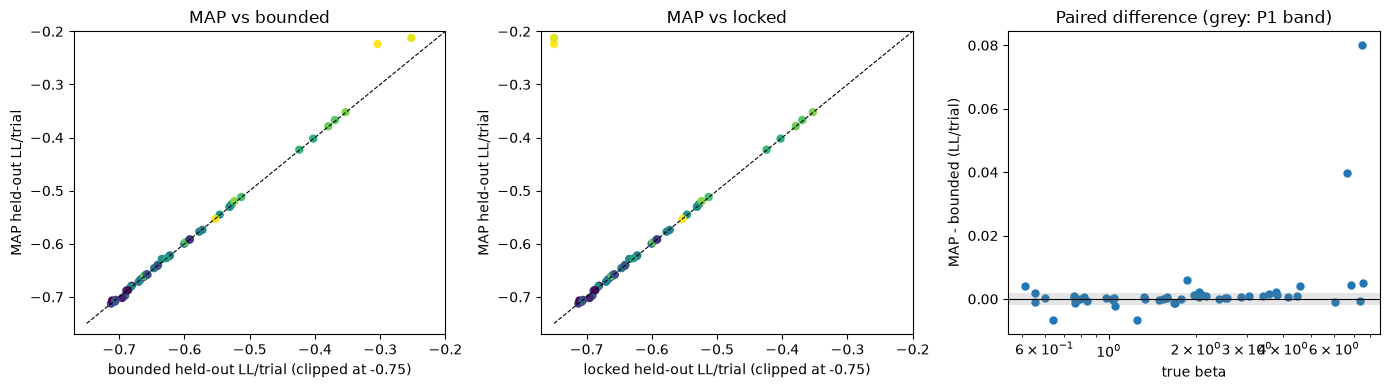

In [5]:
V = ["locked", "bounded", "MAP"]
summary = pd.DataFrame({v: {"mean": cv[v].mean(), "median": cv[v].median(), "min": cv[v].min(),
                            f"n < {CATASTROPHIC}": int((cv[v] < CATASTROPHIC).sum()),
                            "max fold beta": cv[f"{v}_max_beta"].max()} for v in V}).T
display(summary.round(4))

diffs = pd.DataFrame({name: {"median": d.median(), "mean": d.mean(), "q25": d.quantile(0.25),
                             "q75": d.quantile(0.75), "P(MAP better)": (d > 0).mean()}
                      for name, d in [("MAP - bounded", cv["MAP"] - cv.bounded), ("MAP - locked", cv["MAP"] - cv.locked)]}).T
display(diffs.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
lo, hi = -0.75, -0.2
for ax, other in zip(axes[:2], ["bounded", "locked"]):
    ax.scatter(cv[other].clip(lower=lo), cv["MAP"], c=np.log(cv.true_beta), cmap="viridis", s=25)
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    ax.set(xlim=(lo - 0.02, hi), ylim=(lo - 0.02, hi), xlabel=f"{other} held-out LL/trial (clipped at {lo})",
           ylabel="MAP held-out LL/trial", title=f"MAP vs {other}")
d = cv["MAP"] - cv.bounded
axes[2].scatter(cv.true_beta, d, s=25)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].axhspan(-0.002, 0.002, color="grey", alpha=0.2, lw=0)
axes[2].set(xscale="log", xlabel="true beta", ylabel="MAP - bounded (LL/trial)",
            title="Paired difference (grey: P1 band)")
plt.tight_layout(); plt.show()

,spearman alpha,spearman beta,median |log beta err|,"median log-beta bias, true beta<1","median log-beta bias, true beta>=2",n beta_hat > 20,n alpha_hat < 0.01 or > 0.99
locked,0.602,0.886,0.201,0.130,-0.001,0.0,1.0
bounded,0.602,0.886,0.201,0.130,-0.001,0.0,1.0
MAP,0.593,0.891,0.225,0.316,-0.044,0.0,0.0


agents with true beta < 1: 12


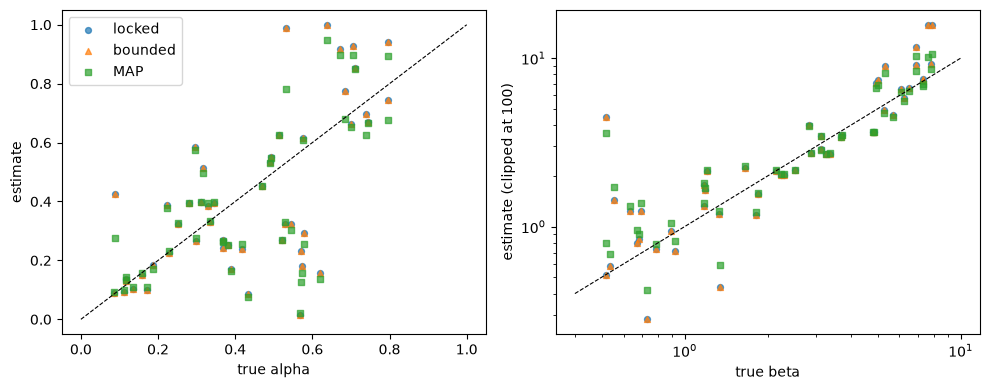

In [6]:
def rec_metrics(prefix):
    lb = np.log(pr[f"{prefix}_beta"]) - np.log(pr.true_beta)
    low = pr.true_beta < 1
    return {"spearman alpha": stats.spearmanr(pr.true_alpha, pr[f"{prefix}_alpha"])[0],
            "spearman beta": stats.spearmanr(pr.true_beta, pr[f"{prefix}_beta"])[0],
            "median |log beta err|": np.median(np.abs(lb)),
            "median log-beta bias, true beta<1": np.median(lb[low]),
            "median log-beta bias, true beta>=2": np.median(lb[pr.true_beta >= 2]),
            "n beta_hat > 20": int((pr[f"{prefix}_beta"] > 20).sum()),
            "n alpha_hat < 0.01 or > 0.99": int(((pr[f"{prefix}_alpha"] < 0.01) | (pr[f"{prefix}_alpha"] > 0.99)).sum())}

rec = pd.DataFrame({v: rec_metrics(v) for v in V}).T
display(rec.round(3))
print("agents with true beta < 1:", int((pr.true_beta < 1).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for v, mk in zip(V, "o^s"):
    axes[0].scatter(pr.true_alpha, pr[f"{v}_alpha"], marker=mk, s=18, alpha=0.7, label=v)
    axes[1].scatter(pr.true_beta, pr[f"{v}_beta"].clip(upper=100), marker=mk, s=18, alpha=0.7, label=v)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set(xlabel="true alpha", ylabel="estimate")
axes[1].plot([0.4, 10], [0.4, 10], "k--", lw=0.8)
axes[1].set(xscale="log", yscale="log", xlabel="true beta", ylabel="estimate (clipped at 100)")
axes[0].legend(); plt.tight_layout(); plt.show()

## 6. Check the predictions (mechanically, against §2)

In [7]:
d_b = cv["MAP"] - cv.bounded
checks = {
    "P1 median(MAP - bounded) in [-0.002, 0.002]": -0.002 <= d_b.median() <= 0.002,
    "P2a mean(MAP - bounded) in [-0.005, 0.005]": -0.005 <= d_b.mean() <= 0.005,
    "P2b P(MAP better than bounded) in [0.3, 0.7]": 0.3 <= (d_b > 0).mean() <= 0.7,
    "P3a no MAP or bounded score < -2": int(((cv["MAP"] < CATASTROPHIC) | (cv.bounded < CATASTROPHIC)).sum()) == 0,
    "P3b if locked has a score < -2, mean(MAP) > mean(locked)":
        (not (cv.locked < CATASTROPHIC).any()) or cv["MAP"].mean() > cv.locked.mean(),
    "P4a no MAP fold beta > 20": cv.MAP_max_beta.max() <= 20,
    "P4b largest MAP fold beta < 15": cv.MAP_max_beta.max() < 15,
    "P5a |Spearman alpha change| < 0.05 (MAP vs locked)":
        abs(rec.loc["MAP", "spearman alpha"] - rec.loc["locked", "spearman alpha"]) < 0.05,
    "P5b |Spearman beta change| < 0.05 (MAP vs locked)":
        abs(rec.loc["MAP", "spearman beta"] - rec.loc["locked", "spearman beta"]) < 0.05,
    "P5c low-beta log bias higher under MAP than ML":
        rec.loc["MAP", "median log-beta bias, true beta<1"] > rec.loc["locked", "median log-beta bias, true beta<1"],
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
print(f"\n{sum(checks.values())}/{len(checks)} predictions held")
print("locked scores < -2 among these agents:", int((cv.locked < CATASTROPHIC).sum()),
      "| P3b condition active:", bool((cv.locked < CATASTROPHIC).any()))

PASS P1 median(MAP - bounded) in [-0.002, 0.002]
PASS P2a mean(MAP - bounded) in [-0.005, 0.005]
PASS P2b P(MAP better than bounded) in [0.3, 0.7]
PASS P3a no MAP or bounded score < -2
PASS P3b if locked has a score < -2, mean(MAP) > mean(locked)
PASS P4a no MAP fold beta > 20
PASS P4b largest MAP fold beta < 15
PASS P5a |Spearman alpha change| < 0.05 (MAP vs locked)
PASS P5b |Spearman beta change| < 0.05 (MAP vs locked)
PASS P5c low-beta log bias higher under MAP than ML

10/10 predictions held
locked scores < -2 among these agents: 2 | P3b condition active: True


## 7. What I learned (written after running §5–6)

**All 10 predictions held, but read that with care.** The bands were set with
knowledge of the locked and bounded results for these agents, and several are
generous. P2b only just passed: MAP beat bounded for 68% of agents, against an
upper limit of 70%. The exercise shows that I understood the mechanism; it does
not independently confirm it.

1. **For held-out prediction, MAP ≈ bounded ML.** Median paired difference
   +0.0005 LL/trial (IQR −0.0001 to +0.0012), mean +0.003, far inside the 0.01
   tie zone. MAP is better slightly more often (68% of agents), because the
   prior nudges extreme estimates toward values that generalise a little better,
   but the gain is negligible.
2. **Either fix removes the scoring pathology.** Two of the 50 locked agents have
   catastrophic held-out scores (worst −1,603 LL/trial; largest fold β̂ ≈ 3.3 × 10⁵),
   which drag the locked mean to −53.4 while its median (−0.638) is ordinary.
   MAP's largest fold β̂ is 10.3, well below the bounded cap of 20: the Gamma
   tail does the work without needing a hard bound.
3. **The price of shrinkage is parameter bias.** Full-data recovery is
   essentially unchanged in rank terms (Spearman α 0.60 → 0.59, β 0.89 → 0.89),
   but MAP pulls β̂ toward the prior mode (3). For the 12 agents with true β < 1,
   the median log-bias rises from +0.13 to +0.32; for β ≥ 2 it becomes slightly
   negative (−0.04), and the median |log β error| worsens (0.20 → 0.23). The
   Beta(1.1, 1.1) prior removed the one α estimate at a bound.
   This is the bias–variance trade-off in one table: better-behaved
   predictions, more biased parameters.
4. **Why this stays out of the report.** It reproduces the bounded conclusion:
   regularisation fixes scoring but does not add identifiability. The priors
   were chosen after the results were known, and the bias in point 3 depends
   directly on where the prior mode sits. A different, equally defensible prior
   (e.g. Gamma(1.2, 5)) would move those numbers. That is precisely the forking
   path the locked design exists to avoid.